# Chapter 2 · Martingales and random walks: interactive demos

Companion to Chapter 2 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/02-martingales.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider

from ieor222.martingales import (doubling, expected_exit_time, first_exit, mean_one_products,
                                 play, prob_upper, random_walk, simulate_exit)
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. Which processes are martingales?

For the walk $S_n = X_1+\dots+X_n$ with steps $+1$ (probability $p$) and $-1$ (probability $q=1-p$),
Corollary 2.4 says that $S_n - n(p-q)$ and $(q/p)^{S_n}$ are martingales, while $S_n$ itself is one
only when $p=\frac12$: otherwise it drifts. A martingale has a constant mean, so its sample mean over many
paths should stay flat.

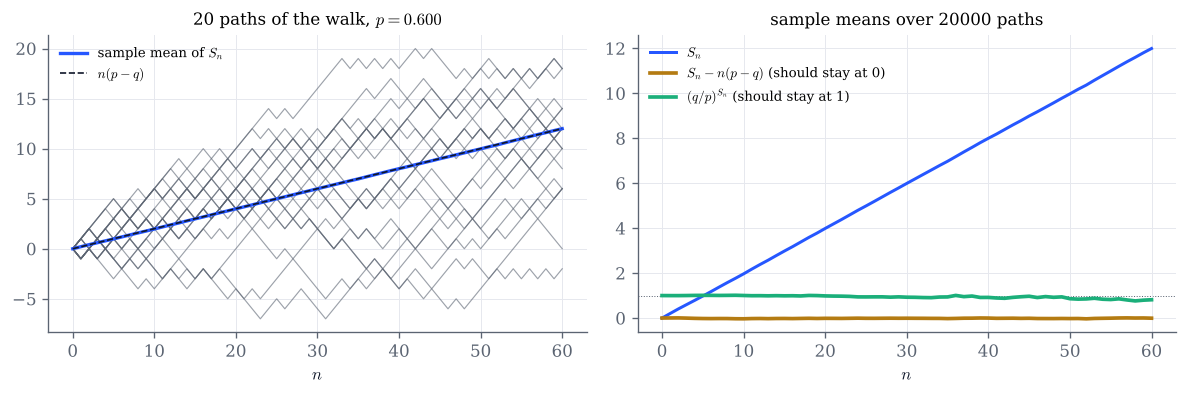

In [2]:
def which_martingales(p=0.6, n_steps=60, n_paths=20_000, seed=0):
    S = random_walk(n_steps, n_paths=n_paths, p=p, seed=seed)
    n = np.arange(n_steps + 1)
    q = 1 - p
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax1.plot(n, S[:20].T, color=GREY, lw=0.7, alpha=0.6)
    ax1.plot(n, S.mean(0), color=COBALT, lw=2, label="sample mean of $S_n$")
    ax1.plot(n, (p - q) * n, color=INK, lw=1, ls="--", label="$n(p-q)$")
    ax1.set(xlabel="$n$", title=f"20 paths of the walk, $p={p:.3f}$")
    ax1.legend(fontsize=8)
    ax2.axhline(0, color=GREY, lw=0.6, zorder=0)
    ax2.axhline(1, color=GREY, lw=0.6, ls=":", zorder=0)
    ax2.plot(n, S.mean(0), color=COBALT, lw=1.8, label="$S_n$")
    ax2.plot(n, (S - (p - q) * n).mean(0), color=GOLD, lw=2.2, label="$S_n - n(p-q)$ (should stay at 0)")
    ax2.plot(n, ((q / p) ** S).mean(0), color=GREEN, lw=2.2, label="$(q/p)^{S_n}$ (should stay at 1)")
    ax2.set(xlabel="$n$", title=f"sample means over {n_paths} paths")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

which_martingales()

In [3]:
# Explore: at p = 1/2 all three coincide with martingales you know; away from 1/2 only S_n drifts.
interact(which_martingales,
         p=FloatSlider(value=0.6, min=0.3, max=0.7, step=0.01, continuous_update=False, description="p"),
         n_steps=IntSlider(value=60, min=10, max=200, step=10, continuous_update=False, description="steps"),
         n_paths=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 2. A martingale whose paths die

Put all your wealth, each period, in a fair bet that returns $+a$ or $-a$. Your wealth
$M_n=\xi_1\cdots\xi_n$, with $\xi_k = 1\pm a$, is a martingale with $\mathbb E[M_n]=1$ (Proposition 2.3(iii)).
Yet $\log M_n$ is a random walk with negative drift $\frac12\log(1-a^2)$ per step, so almost every path goes
to zero (Remark 2.6). The mean is carried by a few lucky paths that a simulation rarely contains.

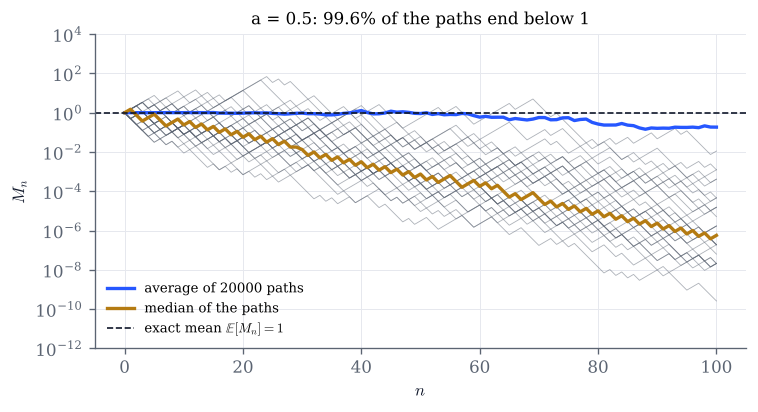

In [4]:
def products(a=0.5, n_steps=100, n_paths=20_000, seed=1):
    M = mean_one_products(n_steps, n_paths=n_paths, a=a, seed=seed)
    n = np.arange(n_steps + 1)
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.plot(n, M[:30].T, color=GREY, lw=0.5, alpha=0.5)
    ax.plot(n, M.mean(0), color=COBALT, lw=2, label=f"average of {n_paths} paths")
    ax.plot(n, np.median(M, axis=0), color=GOLD, lw=2, label="median of the paths")
    ax.axhline(1, color=INK, lw=1, ls="--", label=r"exact mean $\mathbb{E}[M_n]=1$")
    ax.set(yscale="log", ylim=(1e-12, 1e4), xlabel="$n$", ylabel="$M_n$",
           title=f"a = {a}: {100 * np.mean(M[:, -1] < 1):.1f}% of the paths end below 1")
    ax.legend(fontsize=8, loc="lower left")
    plt.show()

products()

In [5]:
# Explore: small a is a mild bet, a = 1 is "double or nothing".
interact(products,
         a=FloatSlider(value=0.5, min=0.05, max=1.0, step=0.05, continuous_update=False, description="a"),
         n_steps=IntSlider(value=100, min=10, max=400, step=10, continuous_update=False, description="steps"),
         n_paths=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. Gambler's ruin

A walk started at $x$ is stopped when it first hits $a=0$ (ruin) or $b$ (target). Theorem 2.17 gives the
probability of reaching the target and Proposition 2.18 the expected duration:
for $p=\frac12$, $\mathbb P(S_\tau=b)=\frac{x}{b}$ and $\mathbb E[\tau]=x(b-x)$; for $p\neq\frac12$, with $r=q/p$,
$\mathbb P(S_\tau=b)=\frac{r^x-1}{r^b-1}$ and $\mathbb E[\tau]=\frac{b\,\mathbb P(S_\tau=b)-x}{p-q}$.
Below, simulated walks against the formulas (lines), with $95\%$ confidence intervals for the simulation.

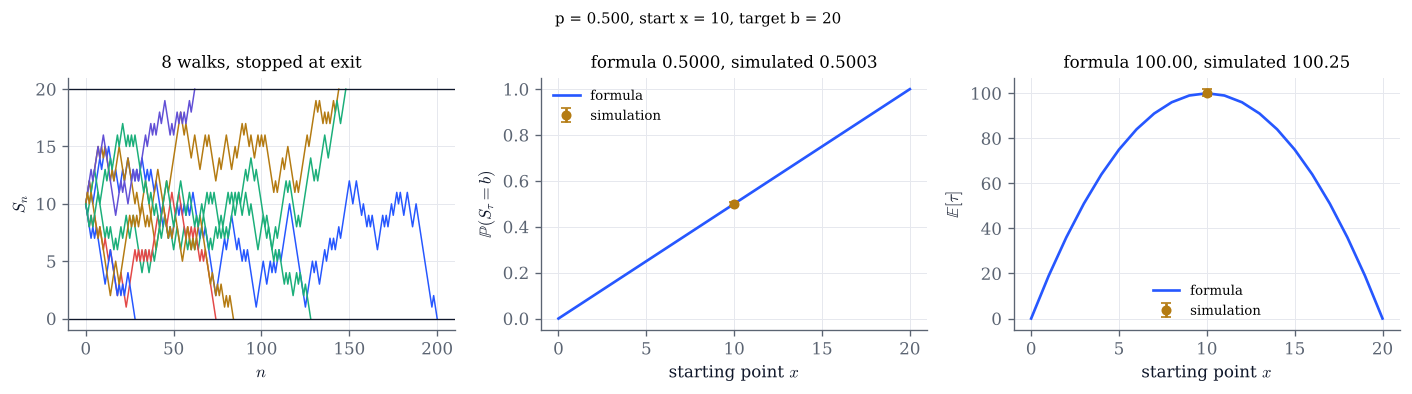

In [6]:
def ruin(p=0.5, x=10, b=20, n_paths=10_000, seed=2):
    x = min(x, b)
    a = 0
    tau, S_tau = simulate_exit(x, a, b, p=p, n_paths=n_paths, seed=seed)
    P_hat, T_hat = np.mean(S_tau == b), tau.mean()
    P_ci = 1.96 * np.sqrt(P_hat * (1 - P_hat) / n_paths)
    T_ci = 1.96 * tau.std() / np.sqrt(n_paths)
    xs = np.arange(a, b + 1)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
    # a few paths, each drawn until it exits
    paths = random_walk(int(4 * max(tau.max(), 10)), n_paths=8, p=p, x0=x, seed=seed + 1)
    t_exit, _ = first_exit(paths, a, b)
    for path, t in zip(paths, t_exit):
        t = len(path) - 1 if t < 0 else t
        axes[0].plot(np.arange(t + 1), path[: t + 1], lw=0.9)
    axes[0].axhline(a, color=INK, lw=0.8); axes[0].axhline(b, color=INK, lw=0.8)
    axes[0].set(xlabel="$n$", ylabel="$S_n$", title="8 walks, stopped at exit")
    axes[1].plot(xs, prob_upper(xs, a, b, p), color=COBALT, label="formula")
    axes[1].errorbar([x], [P_hat], yerr=[P_ci], fmt="o", color=GOLD, ms=5, capsize=3, label="simulation")
    axes[1].set(xlabel="starting point $x$", ylabel=r"$\mathbb{P}(S_\tau=b)$",
                title=f"formula {float(prob_upper(x, a, b, p)):.4f}, simulated {P_hat:.4f}")
    axes[2].plot(xs, expected_exit_time(xs, a, b, p), color=COBALT, label="formula")
    axes[2].errorbar([x], [T_hat], yerr=[T_ci], fmt="o", color=GOLD, ms=5, capsize=3, label="simulation")
    axes[2].set(xlabel="starting point $x$", ylabel=r"$\mathbb{E}[\tau]$",
                title=f"formula {float(expected_exit_time(x, a, b, p)):.2f}, simulated {T_hat:.2f}")
    for ax in axes[1:]:
        ax.legend(fontsize=8)
    fig.suptitle(f"p = {p:.3f}, start x = {x}, target b = {b}", fontsize=9)
    fig.tight_layout()
    plt.show()

ruin()

In [7]:
# Explore: try roulette, p = 18/37 = 0.486, with a far target.
interact(ruin,
         p=FloatSlider(value=0.5, min=0.40, max=0.60, step=0.002, readout_format=".3f", continuous_update=False, description="p"),
         x=IntSlider(value=10, min=0, max=60, continuous_update=False, description="start x"),
         b=IntSlider(value=20, min=2, max=60, continuous_update=False, description="target b"),
         n_paths=IntSlider(value=10_000, min=1_000, max=50_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=2, min=0, max=100, continuous_update=False, description="seed"));

## 4. You cannot beat a fair game

Each strategy chooses its stake for round $k$ from the outcomes of rounds $1,\dots,k-1$ only (the function
`play` enforces this), so its gains are a martingale transform $(H\cdot S)_n$. By Theorem 2.8 the expected
gain is $0$ in a fair game and $\le 0$ in an unfavourable one, whatever the strategy. Many strategies win
*most of the time*; none wins *on average*. The doubling strategy is played with a finite bankroll
$2^m-1$ (Example 2.13).

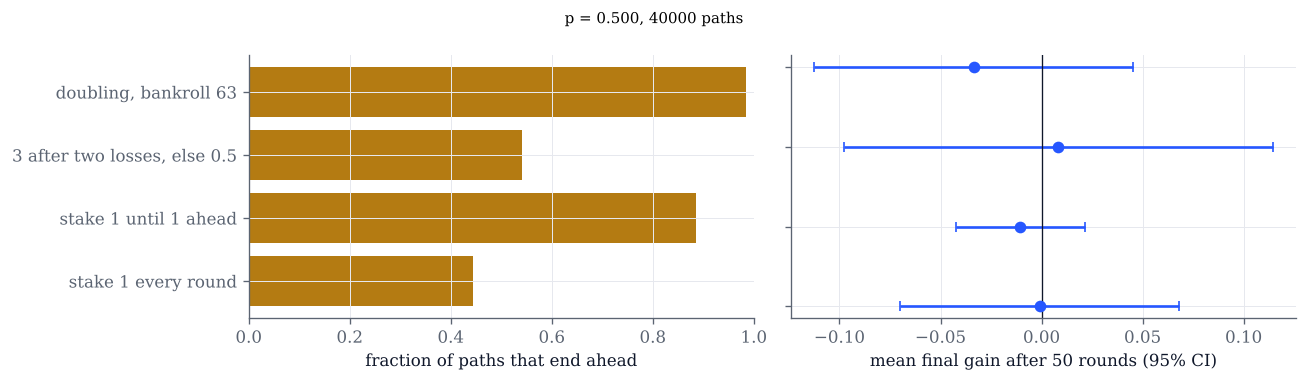

In [8]:
def strategies(m):
    def constant(k, past, gains):
        return np.ones(past.shape[0])
    def until_ahead(k, past, gains):                 # stake 1 until one dollar ahead
        return (gains[:, -1] < 1).astype(float)
    def fallacy(k, past, gains):                     # bet big after two losses in a row
        if k < 3:
            return np.full(past.shape[0], 0.5)
        return np.where((past[:, -1] == -1) & (past[:, -2] == -1), 3.0, 0.5)
    return {"stake 1 every round": constant,
            "stake 1 until 1 ahead": until_ahead,
            "3 after two losses, else 0.5": fallacy,
            f"doubling, bankroll {2**m - 1}": doubling(2**m - 1)}

def fair_game(p=0.5, m=6, n_rounds=50, n_paths=40_000, seed=3):
    names, means, cis, wins = [], [], [], []
    for i, (name, strat) in enumerate(strategies(m).items()):
        _, _, G = play(strat, n_rounds, n_paths=n_paths, p=p, seed=seed + i)
        g = G[:, -1]
        names.append(name); means.append(g.mean())
        cis.append(1.96 * g.std() / np.sqrt(n_paths)); wins.append(np.mean(g > 0))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
    y = np.arange(len(names))
    ax1.barh(y, wins, color=GOLD)
    ax1.set(yticks=y, yticklabels=names, xlim=(0, 1), xlabel="fraction of paths that end ahead")
    ax2.errorbar(means, y, xerr=cis, fmt="o", color=COBALT, capsize=3)
    ax2.axvline(0, color=INK, lw=0.8)
    ax2.set(yticks=y, yticklabels=[], xlabel=f"mean final gain after {n_rounds} rounds (95% CI)")
    fig.suptitle(f"p = {p:.3f}, {n_paths} paths", fontsize=9)
    fig.tight_layout()
    plt.show()

fair_game()

In [9]:
# Explore: move p below 1/2 (an unfavourable game) and change the bankroll 2^m - 1.
interact(fair_game,
         p=FloatSlider(value=0.5, min=0.40, max=0.55, step=0.001, readout_format=".3f", continuous_update=False, description="p"),
         m=IntSlider(value=6, min=1, max=14, continuous_update=False, description="m"),
         n_rounds=IntSlider(value=50, min=5, max=200, step=5, continuous_update=False, description="rounds"),
         n_paths=IntSlider(value=40_000, min=5_000, max=200_000, step=5_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=3, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $p=\frac12$. What do the three curves become, and which martingale of the symmetric walk is missing from the plot?
- In section 2, set $a=1$. Why do all the simulated paths (and probably the average) hit $0$, although $\mathbb E[M_n]=1$?
- In section 3, keep $x$ in the middle of $(0,b)$ and move $p$ from $0.5$ to $0.49$, first with $b=20$, then with $b=60$.
  Why does the same small bias matter so much more when the target is far?
- In section 4, the strategy "stake 1 until 1 ahead" ends ahead on most paths. Increase the number of rounds:
  the fraction of winners grows, yet the mean stays at $0$. Where are the losses hiding?